# Diffusion with an interstitial component

A fast interstitial and a slow substitutional solute share a moving interface.
This Fe-C-Mn-like example uses **synthetic**, nondimensional properties, not real
Fe-C-Mn thermodynamics. Its main lesson is composition basis: the model state and
diffusivity matrices use u-fractions, while physical input/output profiles use mole fractions [3].

Run cells from top to bottom in the `kawin` environment with the package installed.
Start the kernel in this examples directory or at the extraction repository root.
Each notebook is independent; no earlier notebook needs to have been run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from moving_boundary.analytic import FixedMatrixTernaryDiffusivity, recorded_history
from moving_boundary.equilibrium import CallableTernaryInterfaceEquilibrium
from moving_boundary.mesh import CartesianFD1D, ProfileBuilder, StepProfile1D
from moving_boundary.mesh.TransformedGrids import two_phase_landau_grids
from moving_boundary.plotting import plot_interface_history
from moving_boundary.run_diagnostics import inventory_drift
from moving_boundary.solvers import MovingBoundaryIllingworthTernaryFD1DModel

## Define state-basis inputs

FE is dependent, C is interstitial, and MN is substitutional. A pair is ordered
`[C, MN]`. For this system, `u_k = x_k / (1 - x_C)` and the inverse is
`x_k = u_k / (1 + u_C)`. Both entries must be converted, not carbon alone.
Constant matrices have a Mn/C eigenvalue ratio of 0.01 and weak cross coupling.

In [2]:
#NOTES What are the units for length here? I think they are meters but that would be unrealistically large. I understand that it works out because the diffusivities are unrealistically large too (as they would be in m^2/s) and they are just set arbitrarily but I still think it would be nice to set them to realistic values so the user is not confused.
elements, phases = ["FE", "C", "MN"], ["ALPHA", "BETA"]
u_left, u_right = np.array([0.002, 0.015]), np.array([0.010, 0.015])
ratio = 1.0e-2
matrices = {
    "ALPHA": 1.0e-2 * np.array([[1.0, -0.02], [0.0, ratio]]),
    "BETA": 1.0e-3 * np.array([[1.0, -0.05], [0.0, ratio]]),
}
interface_position, domain_length = 0.8 + 1.0e-12, 1.2
duration = 1.0

def x_from_u(u):
    '''Convert both independent components from u to x for this one-interstitial system.'''
    u = np.asarray(u, dtype=float)
    return u / (1.0 + u[..., :1])

def tie_line(eta):
    '''Synthetic equilibrium family, with both endpoints expressed in [u_C, u_MN].'''
    return np.array([0.002, 0.010 + 0.02 * eta]), np.array([0.030 - 0.01 * eta, 0.020 + 0.03 * eta])

closure = CallableTernaryInterfaceEquilibrium(tie_line, eta_bounds=(0.0, 1.0), composition_basis="u")

## Build and solve

Convert the initial profile to mole fractions. The closure explicitly declares
its u basis; the fixed-matrix provider uses that same basis. The physical mesh
and interface-graded phase grids retain the existing demonstration settings.
Temperature is required but does not affect these synthetic constant properties.

In [3]:
mesh = CartesianFD1D(["C", "MN"], [0.0, domain_length], 1198)
mesh.setResponseProfile(ProfileBuilder([
    (StepProfile1D(interface_position, x_from_u(u_left), x_from_u(u_right)), ["C", "MN"])
]))
left_grid, right_grid = two_phase_landau_grids(
    81, 81, method="linear", left_kwargs={"spacing_ratio": 0.05}, right_kwargs={"spacing_ratio": 0.1},
)
model = MovingBoundaryIllingworthTernaryFD1DModel(
    mesh=mesh, elements=elements, phases=phases,
    thermodynamics=FixedMatrixTernaryDiffusivity(matrices, phases), temperature=1000.0,
    interfacePosition=interface_position, interface_equilibrium=closure,
    initial_eta_bracket=(0.0, 1.0), bulk_diffusivity_mode="phase_uniform",
    time_step=1.0, dt_mode="semi_log", semiLog_dt=0.05, semiLogT0=1.0e-6,
    tolerance=1.0e-11, max_iterations=50, terminal_thin_phase_policy="raise", record=True,
    transformed_u_grid=left_grid, transformed_v_grid=right_grid,
    initial_eta_componentwise_scaling=True,
)
model.solve(duration, minDtFrac=1.0e-14, verbose=True, vIt=100)

Iteration	Sim Time (h)	Run time (s)
0		0.000e+00		0.0
100		3.922e-08		0.6
200		5.820e-06		1.0
278		2.778e-04		1.3


## Compare state and physical views

`getTransformedState` returns two independent u-fraction arrays. In contrast,
`getPhysicalPhaseProfiles` returns FE, C, MN mole fractions, preserving the sharp
interface. The carbon curves differ because they use different denominators.

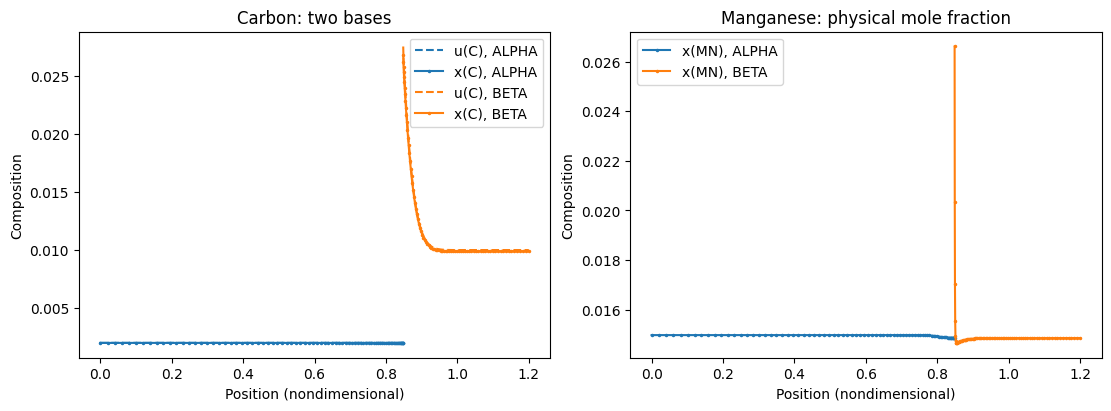

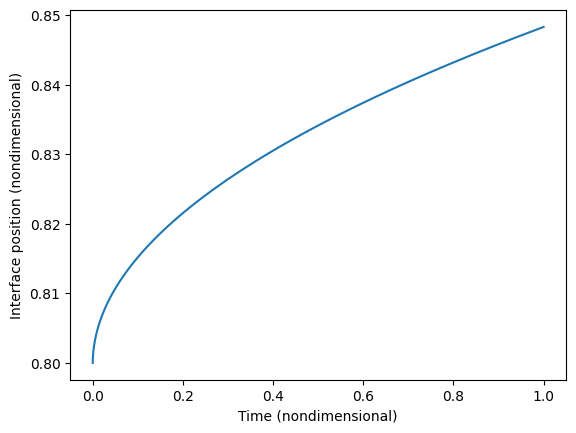

In [9]:
#NOTES I don't think this example makes the differences between the two bases very clear since they are so close to one another it is difficult to see on the plot that they are indeed different.
states = model.getTransformedState()
physical_profiles = model.getPhysicalPhaseProfiles()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for index, (phase, state, (positions, fractions)) in enumerate(zip(phases, states, physical_profiles)):
    axes[0].plot(positions, state[:, 0], "--", color=f"C{index}", label=f"u(C), {phase}")
    axes[0].plot(positions, fractions[:, 1], ".-", markersize=3, color=f"C{index}", label=f"x(C), {phase}")
    axes[1].plot(positions, fractions[:, 2], ".-", markersize=3, label=f"x(MN), {phase}")
for ax in axes:
    ax.set(xlabel="Position (nondimensional)", ylabel="Composition")
    ax.legend()
axes[0].set_title("Carbon: two bases")
axes[1].set_title("Manganese: physical mole fraction")
plt.show()

ax = plot_interface_history(model)
ax.set(xlabel="Time (nondimensional)", ylabel="Interface position (nondimensional)")
plt.show()

## Optional: conservation and the similarity solution

Inventories and the analytic solution use u, so compare them with the state,
not the physical x profiles [1-3]. The constant-property problem has a unique
root for these settings; multiple roots are possible in general [4]. Exact
semi-infinite comparisons apply only before the finite walls affect the profiles.

In [10]:
from moving_boundary.analytic import solve_similarity_roots, compare_model_to_similarity

_, inventories = recorded_history(model.inventoryData)
absolute_drift, relative_drift = inventory_drift(inventories)
roots = solve_similarity_roots(
    matrices["ALPHA"], matrices["BETA"], u_left, u_right, closure,
    s0=interface_position, k_bounds=(1.0e-6, 0.3), n_k=2001,
)
if len(roots) != 1:
    raise ValueError(f"Expected one root for these inputs, found {len(roots)}")
comparison = compare_model_to_similarity(model, roots[0], t_min=0.1, profile_times=[duration])
print(f"Maximum relative inventory drift: {relative_drift:.2e}")
print(f"Relative interface discrepancy against similarity: {comparison['interface_rel_error']:.2e}")

Maximum relative inventory drift: 6.94e-11
Relative interface discrepancy against similarity: 1.65e-03


## Things to try

Change the Mn/C diffusivity ratio, then rebuild and solve. Refine the two grids
independently. If you change component order or add another interstitial, revisit
the conversion formula; this helper is specific to the declared one-interstitial system.

## References


The numbers here are synthetic; the exact solution and the composition basis come from the
literature.

1. J. S. Kirkaldy, "Diffusion in multicomponent metallic systems: III. The motion of planar
   phase interfaces," Can. J. Phys. 36 (1958) 917-925, doi:10.1139/p58-098. Similarity
   solutions for planar interfaces in multicomponent systems with constant diffusivities.
2. D. E. Coates, J. S. Kirkaldy, "Morphological stability of alpha-beta phase interfaces in
   the Cu-Zn-Ni system at 775 C," Metall. Trans. 2 (1971) 3467-3477,
   doi:10.1007/BF02811629. Applies the ternary two-phase similarity solution.
3. J.-O. Andersson, J. Agren, "Models for numerical treatment of multicomponent diffusion in
   simple phases," J. Appl. Phys. 72 (1992) 1350-1355, doi:10.1063/1.351745. The u-fraction
   definition (Eq. (9)), and the assumption that only substitutional elements take up volume
   (Eqs. (4)-(5)).
4. P. Maugis, W. D. Hopfe, J. E. Morral, J. S. Kirkaldy, "Multiple interface velocity
   solutions for ternary biphase infinite diffusion couples," Acta Mater. 45 (1997)
   1941-1954. More than one interface velocity can satisfy the same couple.